# Linear Regression: From Measurements to Least Squares

## 1. Introduction and learning objectives

Suppose a workshop records the number of hours spent on a task and the resulting cost. A line is a small, interpretable model of their relationship. Learning means choosing the line from observations rather than guessing it. The same ideas extend to several measurements per observation: floor area and age might jointly predict a building's energy use.

By the end of this notebook, you should be able to translate a prediction problem into arrays, explain squared error, differentiate the objective, solve a one-feature least-squares problem, and evaluate a fitted model on observations it did not use for fitting. You will distinguish the **model** (a family of possible predictions), the **loss** (how a prediction is scored), and the **fitting method** (how its parameters are chosen).

No previous machine learning is required. You should be able to rearrange a linear equation, work with fractions, and read basic Python. Vectors, matrices, sums, and derivatives are introduced below. The examples use ordinary arithmetic; programming tasks are deliberately left for you.

Read explanations and worked examples first. Each numbered exercise is followed immediately by its own answer cell. Write answers only in those cells on your study branch. Demonstration cells illustrate ideas and can run even while every exercise remains blank.

Try each exercise in its dedicated answer cell first. A collapsed **Show hint** and a separate **Show worked solution — try the exercise first** follow immediately below it. Reference Python is displayed text and is not executed by Run All; some snippets name earlier references in this chapter.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 1.01 — Define a supervised learning problem

**Type:** Conceptual · **Answer:** Markdown

A shop wants to predict daily electricity use from opening hours and outside temperature. Identify one observation, the two inputs, the target, and something this dataset would not establish about causation.

**Expected outcome:** A short paragraph separating measured inputs, the quantity to predict, and the limits of an observational relationship.

**Your response to Exercise 1.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.01**

Treat one day as one row, and distinguish a predictive association from an intervention.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.01**

One observation is a shop-day. Its features are opening hours and outside temperature; its target is the electricity consumed during that day, measured in a stated unit such as kWh. The prediction asks for electricity use on another day with known features.

A relationship between opening hours and consumption does not establish the effect of deliberately extending opening hours. Occupancy, equipment, season, and other factors may change alongside them. Other well-defined observation units are possible, provided features and targets refer to the same unit.

</details>

## 2. Prerequisites and mathematical foundations

### Scalars, vectors, and matrices

A **scalar** is a single real number. $\mathbb{R}$ denotes the real numbers; $\mathbb{R}^d$ denotes vectors with $d$ real entries. A vector is an ordered list. We write a single input $x=(x_1,\ldots,x_d)^T$ as a column, where $T$ means transpose: rows become columns and columns become rows. An index is a label for an entry, not an exponent.

Our dataset contains $n$ examples and $d$ input features. The matrix $X\in\mathbb{R}^{n\times d}$ has one example per row and one feature per column. Thus $X_{ij}$ is feature $j$ of example $i$, with $1\leq i\leq n$ and $1\leq j\leq d$. The targets form $y\in\mathbb{R}^{n}$. In NumPy, we represent these targets with shape `(n,)`; this is a one-dimensional array, not a `(n, 1)` column array.

The parameters are weights $w\in\mathbb{R}^d$ and an intercept $b\in\mathbb{R}$. A hat indicates a prediction rather than an observed value:

$$
\hat y_i=b+\sum_{j=1}^{d}X_{ij}w_j.
$$

The symbol $\sum$ means add the indexed quantities. Weight $w_j$ describes the prediction's change when feature $j$ increases by one unit while other features are fixed. Its units are target units per feature unit. The intercept is the prediction at all-zero inputs, even when that situation is outside the observed range.

A **dot product** multiplies corresponding entries and adds them. For a single example it is $x^T w$. Matrix multiplication performs this dot product for every row:

$$
\hat y=Xw+b\mathbf{1}_n,
$$

where $\mathbf{1}_n$ is the length-$n$ vector of ones. The dimensions are $(n\times d)(d)=n$; the intercept vector also has length $n$. Matrix multiplication is not entrywise multiplication: NumPy uses `@` for the former and `*` for the latter.

**Worked example.** Let $X=\begin{bmatrix}1&2\\0&3\end{bmatrix}$, $w=\begin{bmatrix}2\\-1\end{bmatrix}$, and $b=1$. The first prediction is $1(2)+2(-1)+1=1$; the second is $0(2)+3(-1)+1=-2$. There are two examples and two features. The negative second prediction is allowed for an unconstrained linear model.

### Exercise 1.02 — Practice dimensions and dot products

**Type:** Numerical · **Answer:** Markdown

Use $X=\begin{bmatrix}2&1\\-1&4\\0&2\end{bmatrix}$, $w=(1,2)^T$, and $b=-1$. Compute the three predictions by hand. State the shapes of $X$, $w$, and the NumPy prediction array.

**Expected outcome:** Three scalar predictions and a dimension check showing why each row produces exactly one prediction.

**Your response to Exercise 1.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.02**

Multiply each row by the same two-entry weight vector, then add the scalar intercept once.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.02**

The three predictions are $2(1)+1(2)-1=3$, $-1(1)+4(2)-1=6$, and $0(1)+2(2)-1=3$. Thus $\hat y=(3,6,3)^T$ mathematically.

NumPy shapes are $X:(3,2)$, $w:(2,)$, scalar $b$, and prediction `(3,)`. The matching inner dimension two is the number of features. Entrywise multiplication would not perform the required sum across each row.

</details>

### Change, derivatives, and partial derivatives

A derivative measures local change. For a scalar function $f(t)$, where $t$ is a real input, its derivative is the limiting slope

$$
f'(t)=\lim_{h\to0}\frac{f(t+h)-f(t)}{h}.
$$

Here $h$ is a nonzero perturbation, and the limit asks what happens as its magnitude approaches zero. For $f(t)=t^2$, expanding $(t+h)^2=t^2+2th+h^2$ makes the quotient $2t+h$; taking the limit gives $f'(t)=2t$. For a linear function $at+c$, with constants $a,c$, the derivative is $a$ because adding $h$ changes the function by exactly $ah$.

When a function has several inputs, a **partial derivative** changes one and holds the others fixed. The symbol $\partial J/\partial w_j$ means differentiate the scalar objective $J$ with respect to weight $j$. The **gradient**, written $\nabla_w J$, collects all these partial derivatives in a vector with the same dimension as $w$.

The **chain rule** handles a function inside another function. If $u(t)$ feeds into $f(u)$, then $d f/dt=(d f/du)(du/dt)$. For example, differentiating $(3t+1)^2$ gives $2(3t+1)\cdot3$. The outside square responds to its input, and that input responds to $t$. Derivatives of sums are sums of derivatives, and a constant factor can be moved outside a derivative. We will use precisely these rules.

### Exercise 1.03 — Differentiate a composed expression

**Type:** Mathematical · **Answer:** Markdown

For $f(t)=\frac12(2t-3)^2$, derive $f'(t)$ using the chain rule, and independently by expanding the square. Define the intermediate variable you use.

**Expected outcome:** Two derivations that agree, with a reason for each transformation. Use the next Markdown cell for LaTeX.

**Your response to Exercise 1.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.03**

Name the inside expression and remember to differentiate it as well as the outside square.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.03**

Set $u=2t-3$. Then $f=u^2/2$, so $df/du=u$ and $du/dt=2$. The chain rule gives $f'(t)=2u=4t-6$.

Independently, $f=(4t^2-12t+9)/2=2t^2-6t+9/2$. Differentiating term by term gives $4t-6$ again. The constant term disappears, and both routes describe the same local change.

</details>

## 3. Theoretical development and worked examples

### From residuals to an objective

The **residual** $r_i=\hat y_i-y_i$ measures prediction minus observation. Positive and negative residuals must not cancel when measuring overall error. Squaring each residual makes both signs contribute nonnegative values and penalizes a residual of magnitude four more than one of magnitude two.

We minimize **half the mean squared error**:

$$
J(w,b)=\frac{1}{2n}\sum_{i=1}^n r_i^2
      =\frac{1}{2n}\lVert Xw+b\mathbf1_n-y\rVert_2^2.
$$

The Euclidean norm $\lVert v\rVert_2$ of a vector $v$ is $\sqrt{\sum_i v_i^2}$. Its square is therefore the sum of squared entries. The factor $1/n$ averages over observations. The factor $1/2$ simplifies derivatives. Ordinary mean squared error, abbreviated MSE, is $2J$; report which convention you use. Multiplying an objective by a positive constant changes its gradient's scale but does not change its minimizers.

**Worked example.** Take inputs $(0,1,2)$ and targets $(1,2,2)$, with candidate $w=1/2$ and $b=1$. Predictions are $(1,3/2,2)$, so residuals are $(0,-1/2,0)$. Their squared sum is $1/4$, giving $J=(1/4)/(2\cdot3)=1/24$. The MSE is $1/12$. A small loss means a good fit to these particular observations, not proof that the relationship is causal or that future error is small.

### Exercise 1.04 — Calculate a loss without code

**Type:** Numerical · **Answer:** Markdown

For inputs $(-1,0,2)$, targets $(0,1,4)$, and candidate $w=1$, $b=1$, compute predictions, residuals, half-MSE, and ordinary MSE.

**Expected outcome:** An explicit residual table and both loss values, with the averaging factors shown.

**Your response to Exercise 1.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.04**

Use prediction minus observation for each residual; divide the squared sum by either n or 2n.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.04**

| Input | Target | Prediction | Residual | Squared residual |
| ---: | ---: | ---: | ---: | ---: |
| -1 | 0 | 0 | 0 | 0 |
| 0 | 1 | 1 | 0 | 0 |
| 2 | 4 | 3 | -1 | 1 |

There are $n=3$ observations. Therefore half-MSE is $1/(2\cdot3)=1/6$, and ordinary MSE is $1/3$. Averaging the signed residuals would answer a different question and could conceal cancellation.

</details>

### Deriving the gradient

For one term $\frac12 r_i^2$, the outer derivative is $r_i$. Since $r_i=b+\sum_k X_{ik}w_k-y_i$, changing $w_j$ changes $r_i$ at rate $X_{ij}$. Here $k$ is a summation index over features, used to keep it distinct from the particular feature $j$. By the chain rule,

$$
\frac{\partial J}{\partial w_j}
=\frac1n\sum_{i=1}^n r_i X_{ij},
\qquad
\frac{\partial J}{\partial b}
=\frac1n\sum_{i=1}^n r_i.
$$

The second result uses $\partial r_i/\partial b=1$. Collecting the weight components gives

$$
\nabla_w J=\frac1n X^T r,\qquad r=Xw+b\mathbf1_n-y.
$$

The transpose has shape $(d,n)$, so multiplying by an $n$-entry residual vector produces a $d$-entry gradient. A gradient component says how quickly the loss would increase if that parameter alone increased slightly. A negative component therefore suggests increasing that parameter could reduce the loss locally.

In the previous worked example, the weight gradient is $(0\cdot0+1(-1/2)+2\cdot0)/3=-1/6$. The intercept gradient is also $-1/6$. Neither is zero, so this candidate is not stationary even though two of its predictions are exact.

### Exercise 1.05 — Trace each factor in a derivative

**Type:** Mathematical · **Answer:** Markdown

For the loss $\ell_i=\frac12(b+X_{i1}w_1+X_{i2}w_2-y_i)^2$, derive its partial derivatives with respect to $w_1$, $w_2$, and $b$. Explain why the target's derivative is zero during fitting.

**Expected outcome:** A chain-rule derivation that distinguishes fixed data from adjustable parameters.

**Your response to Exercise 1.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.05**

First differentiate with respect to the residual, then multiply by each residual derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.05**

Let $r_i=b+X_{i1}w_1+X_{i2}w_2-y_i$. The outer derivative of $r_i^2/2$ is $r_i$. Holding the observations and other parameters fixed gives
$$
\frac{\partial\ell_i}{\partial w_1}=r_iX_{i1},\quad
\frac{\partial\ell_i}{\partial w_2}=r_iX_{i2},\quad
\frac{\partial\ell_i}{\partial b}=r_i.
$$
The target is fixed data during parameter fitting, so its derivative with respect to a weight or the intercept is zero. If differentiating with respect to the target itself, the answer would instead be $-\!r_i$; that is a different derivative.

</details>

### Solving the one-feature problem

For one feature, let $\bar x=\frac1n\sum_i x_i$ and $\bar y=\frac1n\sum_i y_i$ be the sample means. At a stationary point the intercept derivative is zero:

$$
0=\sum_i(wx_i+b-y_i)=nw\bar x+nb-n\bar y.
$$

Dividing by the positive integer $n$ and rearranging gives $b=\bar y-w\bar x$. Substituting this into the weight derivative removes the intercept:

$$
0=\sum_i x_i\bigl[w(x_i-\bar x)-(y_i-\bar y)\bigr].
$$

Because $\sum_i(x_i-\bar x)=\sum_i(y_i-\bar y)=0$, replacing the leading $x_i$ by $x_i-\bar x$ does not change this sum. Distribute the product and move the target term to the other side:

$$
w\sum_i(x_i-\bar x)^2
=\sum_i(x_i-\bar x)(y_i-\bar y).
$$

When the denominator is positive, the solution is

$$
w^*=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
           {\sum_i(x_i-\bar x)^2},
\qquad b^*=\bar y-w^*\bar x.
$$

The star labels a minimizing parameter. This is a fitted relationship, not a requirement that the line pass through every point. If all inputs are identical, the denominator is zero: the data cannot distinguish changes in slope from compensating changes in intercept.

For the worked dataset, $\bar x=1$, $\bar y=5/3$, the numerator is $1$, and the denominator is $2$. Thus $w^*=1/2$ and $b^*=7/6$. The optimum adjusts the intercept rather than preserving the exact fit at the endpoints.

### Several features and uniqueness

Define the augmented design matrix $\widetilde X=[\mathbf1_n\;X]$ and parameter vector $\theta=(b,w_1,\ldots,w_d)^T$. The tilde marks the added intercept column, and $\theta\in\mathbb R^{d+1}$. The gradient condition becomes

$$
\widetilde X^T\widetilde X\theta=\widetilde X^T y.
$$

These are the **normal equations**. The matrix on the left is a curvature matrix up to the factor $1/n$: for any vector $v$, $v^T\widetilde X^T\widetilde Xv=\lVert\widetilde Xv\rVert_2^2\geq0$. Thus the quadratic loss is convex: along every line in parameter space it curves upward or is flat. Any stationary point is a global minimizer.

If the columns of $\widetilde X$ are linearly independent, the fitted parameters are unique. Linear independence means no nonzero combination of columns equals zero. Otherwise, several parameters can make the same training predictions. Writing an inverse formula is mathematically possible in the independent case, but explicitly computing that inverse can amplify numerical error. Practical numerical comparisons should use a linear-system or least-squares solver, not an explicit inverse. Implementing numerical matrix factorization is outside this notebook.

### Exercise 1.06 — Recognize non-identifiability

**Type:** Conceptual · **Answer:** Markdown

Two columns record length in metres and the same length in centimetres. Explain whether fitting both creates new information and whether weights must be unique. Distinguish uniqueness of parameters from uniqueness of fitted predictions.

**Expected outcome:** A concrete account of redundant features and compensating parameter changes.

**Your response to Exercise 1.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.06**

Rewrite the two feature contributions using just the measurement in metres.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.06**

If the metre measurement is $x$, the contribution is $w_mx+w_c(100x)=(w_m+100w_c)x$. Only the combined coefficient is identified by these measurements.

For any real $t$, replacing $w_m$ by $w_m-100t$ and $w_c$ by $w_c+t$ leaves predictions unchanged. The duplicate column adds no independent information. For a fixed least-squares design, the fitted training prediction vector is unique as the projection onto the design's column space, although the coefficient vector need not be. Extra constraints or a penalty can select particular coefficients, but do not create new measured information.

</details>

## 4. Guided exercises

### Exercise 1.07 — Compute a full gradient

**Type:** Numerical · **Answer:** Markdown

Use $X=\begin{bmatrix}1&0\\0&2\end{bmatrix}$, $y=(2,1)^T$, $w=(0,1)^T$, and $b=0$. Compute predictions, residuals, $J$, $\nabla_w J$, and $\partial J/\partial b$ by hand.

**Expected outcome:** A scalar loss, a two-entry weight gradient, and one intercept gradient, with dimensions checked.

**Your response to Exercise 1.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.07**

Compute the residual vector first; the weight gradient has two components and the bias gradient is a scalar.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.07**

Predictions are $(0,2)^T$ and residuals $r=(-2,1)^T$. Hence
$$
J=\frac{(-2)^2+1^2}{2\cdot2}=\frac54,\qquad
\nabla_wJ=\frac12
\begin{bmatrix}1&0\\0&2\end{bmatrix}
\begin{bmatrix}-2\\1\end{bmatrix}
=\begin{bmatrix}-1\\1\end{bmatrix},
\qquad
\frac{\partial J}{\partial b}=\frac{-2+1}{2}=-\frac12.
$$
The gradient with respect to weights has shape `(2,)` and the intercept derivative is scalar.

</details>

### Exercise 1.08 — Derive a constant-input limitation

**Type:** Mathematical · **Answer:** Markdown

Suppose $x_i=c$ for all observations, where $c$ is a fixed real number. Show that predictions depend only on $wc+b$. Describe an infinite family of parameter pairs with the same predictions.

**Expected outcome:** An algebraic argument for non-uniqueness, rather than a division by a zero denominator.

**Your response to Exercise 1.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.08**

Keep the combined value wc + b fixed while changing w.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.08**

Every prediction is $s=wc+b$. Choose any real $t$ and define $w'=w+t$ and $b'=b-ct$. Then $w'c+b'=(w+t)c+b-ct=wc+b=s$.

Thus infinitely many parameter pairs produce exactly the same predictions. If $c=0$, the weights do not affect predictions at all. At a least-squares optimum the shared prediction is the target mean, but the slope remains unidentified.

</details>

## 5. Implementation challenges

Use NumPy arrays, not a machine learning library. Define functions in the cells below. Do not put fitting code into the demonstration cells. NumPy's one-dimensional convention needs care: subtracting a `(n, 1)` target from a `(n,)` prediction broadcasts into an `(n, n)` array, silently creating the wrong loss. Check dimensions explicitly before arithmetic.

### Exercise 1.09 — Implement predictions with an explicit contract

**Type:** Programming · **Answer:** Code

Write `predict_linear(X, w, b)` for `X.shape == (n, d)`, `w.shape == (d,)`, and scalar `b`. Return shape `(n,)`. Reject incompatible shapes with clear errors. Keep this function responsible only for prediction.

**Expected outcome:** A readable function plus checks for one feature, several features, and a rejected column-shaped weight array. Use tiny examples of your own.

In [ ]:
# Your code for Exercise 1.09.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.09**

Check ranks before multiplication; scalar broadcasting is intended, target-style broadcasting is not.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.09**

This reference explicitly rejects malformed and nonfinite inputs. An empty prediction batch is allowed; the loss routine will require observations.

~~~python
def predict_linear(X, w, b):
    X = np.asarray(X, dtype=float)
    w = np.asarray(w, dtype=float)
    b_array = np.asarray(b, dtype=float)
    if X.ndim != 2 or w.ndim != 1 or b_array.ndim != 0:
        raise ValueError("Expected X (n,d), w (d,), and scalar b")
    if X.shape[1] != w.size:
        raise ValueError("Feature and weight dimensions do not match")
    if not (np.isfinite(X).all() and np.isfinite(w).all()
            and np.isfinite(b_array).all()):
        raise ValueError("Inputs must be finite")
    return X @ w + float(b_array)

np.testing.assert_allclose(
    predict_linear([[1], [3]], [2], 1), [3, 7])
np.testing.assert_allclose(
    predict_linear([[1, 2], [0, 3]], [2, -1], 1), [1, -2])
try:
    predict_linear([[1, 2]], [[2], [-1]], 1)
except ValueError:
    pass
else:
    raise AssertionError("Column-shaped weights should be rejected")
~~~

</details>

### Exercise 1.10 — Implement the half-MSE and its gradient

**Type:** Programming · **Answer:** Code

Write `linear_loss_and_gradient(X, y, w, b)` returning the scalar half-MSE, weight gradient of shape `(d,)`, and scalar intercept gradient. Reuse your prediction function. Require nonempty observations and a one-dimensional target.

**Expected outcome:** Values checked against at least two manual calculations, and an explanation in comments of where division by the number of observations occurs.

In [ ]:
# Your code for Exercise 1.10.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.10**

Use a single residual vector, and apply its observation average once to each returned quantity.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.10**

This uses `predict_linear` from Solution 1.09. The intercept gradient is a scalar mean, not a vector of per-example values.

~~~python
def linear_loss_and_gradient(X, y, w, b):
    prediction = predict_linear(X, w, b)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if y.ndim != 1 or y.shape != prediction.shape or y.size == 0:
        raise ValueError("Expected nonempty targets with shape (n,)")
    if not np.isfinite(y).all():
        raise ValueError("Targets must be finite")
    residual = prediction - y
    n = y.size
    return (float(residual @ residual / (2 * n)),
            X.T @ residual / n, float(residual.mean()))

loss, dw, db = linear_loss_and_gradient(
    [[1, 0], [0, 2]], [2, 1], [0, 1], 0)
np.testing.assert_allclose([loss, *dw, db], [1.25, -1, 1, -0.5])
loss, dw, db = linear_loss_and_gradient(
    [[0], [1], [2]], [1, 2, 2], [0.5], 1)
np.testing.assert_allclose([loss, dw[0], db], [1/24, -1/6, -1/6])
~~~

</details>

### Exercise 1.11 — Fit the one-feature model analytically

**Type:** Programming · **Answer:** Code

Write `fit_one_feature(x, y)` using the means and sums derived above. Return a slope and intercept. Detect the constant-input case and explain your chosen behavior. Do not use `polyfit`, a fitted estimator, or a numerical least-squares solver for this task.

**Expected outcome:** An independently checked fit, near-zero gradients at a nondegenerate optimum, and a deliberate response to an unidentifiable slope.

In [ ]:
# Your code for Exercise 1.11.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.11**

Center both arrays first; a zero denominator signals a modeling issue rather than a small floating-point adjustment.

Center both arrays, and distinguish a truly zero denominator from a merely small scale.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.11**

This policy raises an error rather than silently inventing an identifiable slope. A different documented policy could return the constant predictor with slope zero.

~~~python
def fit_one_feature(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.ndim != 1 or y.shape != x.shape or x.size == 0:
        raise ValueError("Expected nonempty, equally shaped 1D arrays")
    if not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError("Data must be finite")
    xc, yc = x - x.mean(), y - y.mean()
    denominator = float(xc @ xc)
    if denominator == 0:
        raise ValueError("The slope is unidentifiable for constant inputs")
    slope = float(xc @ yc / denominator)
    intercept = float(y.mean() - slope * x.mean())
    return slope, intercept

np.testing.assert_allclose(
    fit_one_feature([0, 1, 2], [1, 2, 2]), [0.5, 7/6])
~~~

The zero test concerns identifiability. Very poorly scaled inputs can still create numerical problems even with a nonzero denominator; scaling and inspection are preferable to an arbitrary absolute cutoff.

</details>

### Exercise 1.12 — Design numerical checks

**Type:** Programming · **Answer:** Code

Write small assertion-based checks for your functions. Include a perfectly fitted dataset, an imperfectly fitted dataset, a constant-input dataset, and a target with the wrong shape. Use numerical tolerances rather than exact floating-point equality.

**Expected outcome:** Checks that detect at least one plausible bug, such as forgetting the intercept or averaging twice. Explain what each check protects.

In [ ]:
# Your code for Exercise 1.12.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.12**

Include cases with a nonzero intercept and cases that must fail before any arithmetic is broadcast.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.12**

These checks use Solutions 1.09–1.11. They protect observable behavior rather than matching internal code.

~~~python
x = np.array([-1., 0., 1.])
w, b = fit_one_feature(x, 3*x + 2)
np.testing.assert_allclose([w, b], [3, 2])
loss, dw, db = linear_loss_and_gradient(x[:, None], 3*x + 2, [w], b)
np.testing.assert_allclose([loss, dw[0], db], 0, atol=1e-12)
np.testing.assert_allclose(predict_linear([[0]], [3], 2), [2])

w, b = fit_one_feature([0, 1, 2], [1, 2, 2])
loss, dw, db = linear_loss_and_gradient(
    np.arange(3)[:, None], [1, 2, 2], [w], b)
np.testing.assert_allclose([loss, dw[0], db], [1/36, 0, 0], atol=1e-12)
for operation in [
    lambda: fit_one_feature([1, 1], [2, 3]),
    lambda: linear_loss_and_gradient([[0], [1]], [[0], [1]], [1], 0),
]:
    try:
        operation()
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid input was accepted")
~~~

The nonzero-intercept assertion catches an omitted bias; the imperfect fit catches a loss that incorrectly reports zero; rejecting column targets prevents an accidental square residual matrix.

</details>

## 6. Experiments and visualizations

The following cell is a demonstration of residual geometry, not a fitting algorithm. A vertical segment measures prediction minus observation at a fixed input. The horizontal reference is intentionally chosen rather than learned.

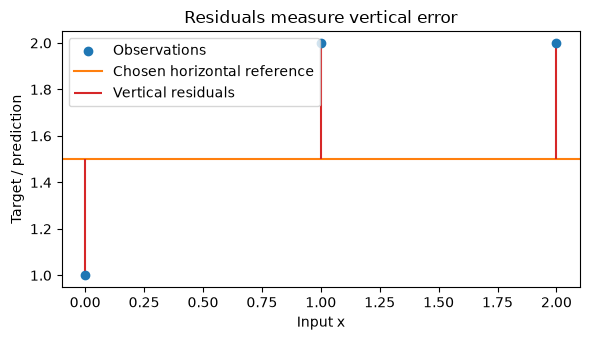

In [6]:
import numpy as np
import matplotlib.pyplot as plt

demo_x = np.array([0.0, 1.0, 2.0])
demo_y = np.array([1.0, 2.0, 2.0])
demo_reference = np.full(3, 1.5)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(demo_x, demo_y, label="Observations", zorder=3)
ax.axhline(1.5, color="tab:orange", label="Chosen horizontal reference")
ax.vlines(demo_x, demo_reference, demo_y, color="tab:red", label="Vertical residuals")
ax.set(xlabel="Input x", ylabel="Target / prediction", title="Residuals measure vertical error")
ax.legend()
fig.tight_layout()
plt.show()

### Moving a line and reading its loss surface

Changing a slope rotates the prediction line, while changing an intercept
shifts it vertically. The left panel compares three chosen parameter pairs
on a new four-observation toy dataset. Their labels show half-MSE,
$J(w,b)=\frac1{2n}\sum_i(wx_i+b-y_i)^2$.

The right panel evaluates that same scalar loss over a grid of slopes and
intercepts. Each marked point is the corresponding line from the left panel.
Contour curves join parameter pairs with equal loss; smaller labels indicate
less squared error on these four observations. The candidates are illustrative
choices, not the output of a fitting routine. None uses the later held-out
exercise dataset.

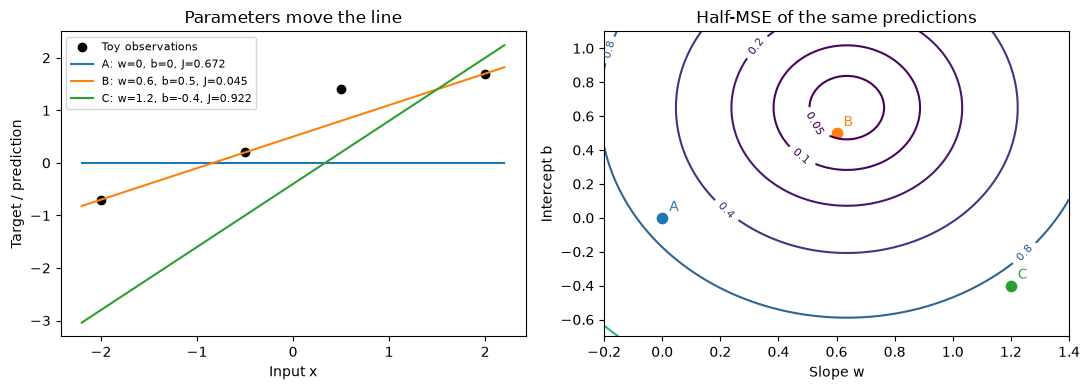

In [3]:
intuition_x = np.array([-2., -.5, .5, 2.])
intuition_y = np.array([-.7, .2, 1.4, 1.7])
intuition_candidates = [(0., 0.), (.6, .5), (1.2, -.4)]
intuition_labels = ["A", "B", "C"]
intuition_colors = ["tab:blue", "tab:orange", "tab:green"]
intuition_line_x = np.linspace(-2.2, 2.2, 100)
intuition_slopes, intuition_biases = np.meshgrid(
    np.linspace(-.2, 1.4, 100), np.linspace(-.7, 1.1, 100)
)
intuition_grid_residuals = (
    intuition_slopes[..., None] * intuition_x
    + intuition_biases[..., None] - intuition_y
)
intuition_loss_surface = np.mean(intuition_grid_residuals**2, axis=-1) / 2
intuition_figure, intuition_axes = plt.subplots(1, 2, figsize=(11, 4))
intuition_axes[0].scatter(intuition_x, intuition_y, color="black", label="Toy observations")
intuition_contours = intuition_axes[1].contour(
    intuition_slopes, intuition_biases, intuition_loss_surface,
    levels=[.05, .1, .2, .4, .8, 1.6, 2.4],
)
intuition_axes[1].clabel(intuition_contours, fontsize=8, fmt="%g")
intuition_candidate_losses = []
for (intuition_w, intuition_b), intuition_label, intuition_color in zip(
    intuition_candidates, intuition_labels, intuition_colors
):
    intuition_loss = np.mean((intuition_w * intuition_x + intuition_b - intuition_y)**2) / 2
    intuition_candidate_losses.append(float(intuition_loss))
    intuition_axes[0].plot(
        intuition_line_x, intuition_w * intuition_line_x + intuition_b,
        color=intuition_color,
        label=f"{intuition_label}: w={intuition_w:g}, b={intuition_b:g}, J={intuition_loss:.3f}",
    )
    intuition_axes[1].scatter(intuition_w, intuition_b, color=intuition_color, s=55)
    intuition_axes[1].annotate(
        intuition_label, (intuition_w, intuition_b), xytext=(5, 5),
        textcoords="offset points", color=intuition_color,
    )
intuition_axes[0].set(xlabel="Input x", ylabel="Target / prediction", title="Parameters move the line")
intuition_axes[0].legend(fontsize=8)
intuition_axes[1].set(xlabel="Slope w", ylabel="Intercept b", title="Half-MSE of the same predictions")
intuition_figure.tight_layout()
plt.show()

### Training data, test data, and assumptions

A fitted model has already adapted to its training data. A **test set** contains held-out observations used to estimate performance after modeling decisions are finished. During repeated model selection, use a separate validation set and reserve the test set for final evaluation. Small datasets produce uncertain estimates; one split is not a universal conclusion.

Least squares can be calculated without assuming Gaussian noise. Interpreting a line as a conditional mean is reasonable when the mean relationship is approximately linear and omitted effects do not systematically shift the error at a fixed input. Independence and constant variance matter for particular statistical uncertainty claims, but are not prerequisites for computing the minimum. Outliers have large influence because the residual is squared. Extrapolation, meaning prediction beyond the observed input range, can fail even when training error is tiny.

The next cell creates a reproducible toy dataset and a fixed train/test split. `default_rng` makes a random-number generator; its seed fixes this demonstration's random sequence. The noise distribution `normal(0, 0.4, ...)` has mean zero and standard deviation $0.4$. A permutation rearranges indices without repeating or dropping observations. No parameters are fitted here.

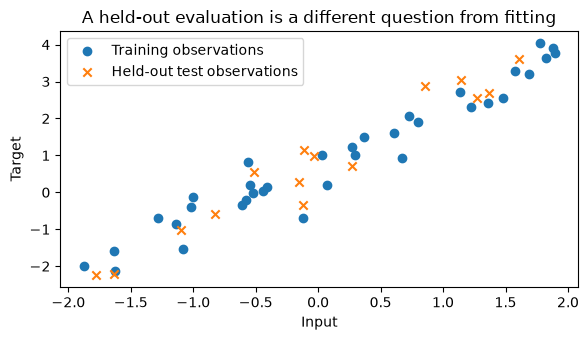

Training shapes: (35, 1) (35,)
Test shapes: (15, 1) (15,)


In [7]:
demo_rng = np.random.default_rng(101)
demo_X = demo_rng.uniform(-2.0, 2.0, size=(50, 1))
demo_targets = 0.8 + 1.5 * demo_X[:, 0] + demo_rng.normal(0.0, 0.4, size=50)
demo_order = demo_rng.permutation(50)
demo_train, demo_test = demo_order[:35], demo_order[35:]
demo_X_train, demo_y_train = demo_X[demo_train], demo_targets[demo_train]
demo_X_test, demo_y_test = demo_X[demo_test], demo_targets[demo_test]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(demo_X_train[:, 0], demo_y_train, label="Training observations")
ax.scatter(demo_X_test[:, 0], demo_y_test, marker="x", label="Held-out test observations")
ax.set(xlabel="Input", ylabel="Target", title="A held-out evaluation is a different question from fitting")
ax.legend()
fig.tight_layout()
plt.show()
print("Training shapes:", demo_X_train.shape, demo_y_train.shape)
print("Test shapes:", demo_X_test.shape, demo_y_test.shape)

### Exercise 1.13 — Fit and evaluate a held-out dataset

**Type:** Experimental · **Answer:** Code

Use the supplied training arrays with your analytical fitter. Plot the fitted line over the observed input range. Compute ordinary MSE on training and test observations, without refitting on the test set.

**Expected outcome:** A labeled plot, two clearly named error values, and reproducible parameters. A particular ordering of train and test error is not guaranteed for one small split.

In [ ]:
# Your code for Exercise 1.13.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.13**

Fit only with the supplied training rows; use the same fitted parameters for both error calculations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.13**

Run the dataset demonstration first. This uses Solutions 1.09 and 1.11 and evaluates ordinary MSE, not half-MSE.

~~~python
ref_w, ref_b = fit_one_feature(demo_X_train[:, 0], demo_y_train)
ref_train_mse = np.mean(
    (predict_linear(demo_X_train, [ref_w], ref_b) - demo_y_train)**2)
ref_test_mse = np.mean(
    (predict_linear(demo_X_test, [ref_w], ref_b) - demo_y_test)**2)
print({"slope": ref_w, "intercept": ref_b,
       "training_MSE": ref_train_mse, "test_MSE": ref_test_mse})
ref_grid = np.linspace(demo_X.min(), demo_X.max(), 150)
fig, ax = plt.subplots()
ax.scatter(demo_X_train[:, 0], demo_y_train, label="Train")
ax.scatter(demo_X_test[:, 0], demo_y_test, marker="x", label="Test")
ax.plot(ref_grid, ref_w * ref_grid + ref_b, label="Fit from training data")
ax.set(xlabel="Input", ylabel="Target", title="Held-out linear fit")
ax.legend()
plt.show()
~~~

The fitted coefficients should be interpreted relative to the data's noise and finite sample, not required to equal the generating coefficients exactly. Either train/test error ordering is possible for one random split. The printed values are measurements of this run, not universal performance claims.

</details>

### Exercise 1.14 — Investigate one influential observation

**Type:** Experimental · **Answer:** Code

Copy the training targets and alter one value by a large amount. Refit on the altered training data, keeping the test set unchanged. Compare the fitted parameters and both error measures across at least three perturbation magnitudes.

**Expected outcome:** A table or plot documenting the perturbations and their effects. Preserve the original arrays so your baseline remains reproducible.

In [ ]:
# Your code for Exercise 1.14.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.14**

Copy the targets, vary one perturbation, and keep all test observations and fitting settings fixed.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.14**

The following reference reuses the preceding functions and demonstration data. It preserves the baseline arrays.

~~~python
ref_perturbations = [0., 5., 20., 80.]
ref_rows = []
for delta in ref_perturbations:
    altered = demo_y_train.copy()
    altered[0] += delta
    slope, intercept = fit_one_feature(demo_X_train[:, 0], altered)
    train_mse = np.mean(
        (predict_linear(demo_X_train, [slope], intercept) - altered)**2)
    test_mse = np.mean(
        (predict_linear(demo_X_test, [slope], intercept) - demo_y_test)**2)
    ref_rows.append((delta, slope, intercept, train_mse, test_mse))
print("delta, slope, intercept, training MSE, unchanged-test MSE")
print(np.array(ref_rows))
fig, ax = plt.subplots()
ax.plot(ref_perturbations, [row[4] for row in ref_rows], "o-")
ax.set(xlabel="Added target perturbation", ylabel="Test MSE",
       title="Influence of one altered training target")
plt.show()
~~~

For a perturbation $\Delta$ to target $i$, the slope changes by $\Delta(x_i-\bar x)/\sum_k(x_k-\bar x)^2$ and the intercept changes by $\Delta/n-\bar x\,\Delta w$. Thus influence depends on both residual magnitude and feature position. Test error need not increase monotonically for every small perturbation; inspect the actual table.

</details>

## 7. Interpretation and critical analysis

Prediction quality, interpretability, and causality are different claims. A coefficient depends on feature units and on what other features are included. Correlated features can make coefficients unstable while predictions barely change. An intercept outside the relevant input range may have little practical meaning. A model that always predicts a nonnegative quantity can still produce negative values because this linear family has no such constraint.

Inspect residuals against inputs and fitted values: a curved pattern suggests a missed nonlinear mean relationship, while changing spread suggests variable noise magnitude. Neither pattern alone identifies its cause. Data collection, measurement error, leakage, and an unrepresentative test set can undermine conclusions before any algorithm is involved.

### Exercise 1.15 — Audit a persuasive-looking result

**Type:** Critical · **Answer:** Markdown

A model predicts a physical quantity that cannot be negative. Its training MSE is low, but it gives negative predictions for small inputs outside the training range. Explain two distinct reasons the training score is insufficient, and propose a defensible next investigation.

**Expected outcome:** A critique addressing both evaluation and model assumptions, without claiming that clipping predictions automatically fixes the model.

**Your response to Exercise 1.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.15**

Separate predictions outside the observed range from whether the model respects the target's support.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.15**

A low training MSE evaluates observations already used for fitting; it does not establish future error or validity outside their input range. Separately, this model family permits negative outputs even though the target cannot be negative.

Investigate where the intended deployment inputs lie, inspect held-out residuals, and check whether extrapolation is supported by domain knowledge. A constrained model or a justified transformed target may be appropriate. Clipping alone changes predictions without repairing unsupported assumptions, and can conceal the underlying extrapolation problem.

</details>

### Exercise 1.16 — Interpret your outlier experiment

**Type:** Critical · **Answer:** Markdown

Explain why squared error can make a single observation influential. Separate what you observed in your particular experiment from what is mathematically guaranteed. Discuss when deleting an unusual observation would be unjustified.

**Expected outcome:** A written interpretation grounded in residual weighting and the data-collection context.

**Your response to Exercise 1.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.16**

Differentiate one half-squared residual and distinguish an unusual response from a high-leverage input.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.16**

For $\ell=r^2/2$, $d\ell/dr=r$: a large residual has proportionally greater influence on the gradient. An input far from the training mean can additionally have high leverage on the slope.

The experiment establishes the effect of its particular artificial perturbation on a fixed split. It does not prove that every unusual observation is erroneous or that every perturbation worsens test error. Verify measurement, units, data collection, and whether the observation belongs to the population of interest. Removing a legitimate difficult observation merely to improve a score would bias the study.

</details>

## 8. Review questions and knowledge checks

### Exercise 1.17 — Separate the components of learning

**Type:** Conceptual · **Answer:** Markdown

Explain the roles of the model, objective, gradient, and fitted parameters. Which part changes when we later use gradient descent to fit the same linear model? Why can a zero gradient here identify a global minimum without guaranteeing a unique parameter vector?

**Expected outcome:** A connected explanation using convexity and feature dependence appropriately.

**Your response to Exercise 1.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.17**

Distinguish a family of predictions from the numerical procedure used to choose one member.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.17**

The model is $\hat y=Xw+b\mathbf1$, the objective is half-MSE, the gradient describes local objective changes, and the fitted parameters specify the chosen line or hyperplane. Replacing the analytical solution by gradient descent changes the fitting method; the model family and objective can remain identical.

The least-squares Hessian is positive semidefinite, so a stationary point is a global minimum of this convex quadratic. If design columns are dependent, flat parameter directions remain and several parameter vectors give the same fitted predictions. Global optimality therefore does not imply coefficient uniqueness.

</details>

### Exercise 1.18 — Track a change of loss convention

**Type:** Mathematical · **Answer:** Markdown

Replace half-MSE by ordinary MSE. Derive the new gradients and explain why the minimizing parameters stay the same. Predict what this rescaling could require of a future iterative fitting method's step size.

**Expected outcome:** A derivation distinguishing an unchanged optimization target from a changed gradient magnitude.

**Your response to Exercise 1.18**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 1.18**

Multiplication by a positive constant rescales derivatives but preserves which objective values are smallest.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 1.18**

With $M=2J$, linearity of differentiation gives
$$
\nabla_wM=\frac{2}{n}X^Tr,\qquad
\frac{\partial M}{\partial b}=\frac{2}{n}\sum_i r_i.
$$
For any two parameter vectors, $J(\theta_1)\leq J(\theta_2)$ exactly when $2J(\theta_1)\leq2J(\theta_2)$, so the minimizers are unchanged.

For identical gradient-descent trajectories from the same initial parameters, use half the learning rate with MSE: $\alpha_M=\alpha_J/2$. Gradient- or loss-based stopping tolerances also need to respect the changed scale.

</details>

## 9. Summary and next learning steps

You now have a complete route from data shapes to least squares: define a linear prediction, measure residuals, average their squared magnitudes, differentiate carefully, and solve the stationary equations. One-feature fitting can be done with sums; multiple features require attention to dependence and numerical stability. Evaluation uses held-out data and scientific judgment, not only an optimized training score.

Before continuing, check that your written derivations name their symbols, your functions keep `(n,)` targets separate from `(n, 1)` arrays, and your experiment records its seed and loss convention. Leave these answers on your study branch.

Next: [Gradient Descent](gradient-descent.ipynb) develops iterative fitting when direct formulas are unavailable or costly. Its first example uses a single scalar so that optimization can be understood before it is applied to a full dataset.